# Week 6 — Finalizing Models
## Financial Risk Layer — Taiwan Bankruptcy Prediction

**Owner:** Ankit Kumar  |  **Track:** Financial Layer  |  **CLO 3 / 4 / 5**

Week 5 shortlisted **XGBoost** for the financial layer. This notebook fine-tunes it via
randomized hyperparameter search, re-tunes Random Forest as an honest check on that
ranking, calibrates the decision threshold, and evaluates the result on the held-out
test set exactly once.

| Artifact (unchanged from Week 4/5) | Shape |
|---|---|
| `financial_X_train_processed.csv` | 5,455 × 85 |
| `financial_X_test_processed.csv` | 1,364 × 85 |
| `financial_y_train.csv` / `financial_y_test.csv` | target = `Bankrupt?` |

**Two constraints carry over from Week 5 and drive every design choice below.**

1. **The target is severely imbalanced** — 3.23% bankrupt. Accuracy is meaningless here
   (predicting "not bankrupt" for every firm scores 96.8%), so the search optimises
   **average precision (PR-AUC)**, not accuracy.
2. **The test set holds only 44 bankrupt firms.** One firm moving across the decision
   boundary shifts recall by 2.3 points. So the test set is *sealed* until Section 7 —
   all tuning and all threshold selection happen on a validation split carved out of the
   training rows. Touching the test set to pick a hyperparameter or a threshold would
   turn it into a training set and make the final number a fiction.

## 1. Setup and loading the Week 4 artifacts

In [1]:
import os
import warnings

# Set before joblib spawns worker processes, which do not inherit filterwarnings.
os.environ["PYTHONWARNINGS"] = "ignore"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import sklearn
import xgboost
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedKFold, train_test_split,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve,
)

RANDOM_STATE = 42
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)
warnings.filterwarnings("ignore")   # keeps joblib/sklearn chatter out of the results

print("Libraries loaded.")
print(f"scikit-learn {sklearn.__version__}  |  xgboost {xgboost.__version__}  |  pandas {pd.__version__}")

Libraries loaded.
scikit-learn 1.9.0  |  xgboost 3.4.0  |  pandas 3.0.3


In [2]:
# Locate the Week 4 outputs. Works in Colab (files uploaded to /content),
# in Google Drive, or from a local working directory.
REQUIRED = [
    "financial_X_train_processed.csv",
    "financial_X_test_processed.csv",
    "financial_y_train.csv",
    "financial_y_test.csv",
]

SEARCH_DIRS = [
    ".", "data", "week6/data", "project/week6/data",
    "/content", "/content/drive/MyDrive",
    "/content/drive/MyDrive/CEROP",
]

DATA_DIR = next(
    (d for d in SEARCH_DIRS
     if all(os.path.exists(os.path.join(d, f)) for f in REQUIRED)),
    None,
)

if DATA_DIR is None:
    # Colab fallback: prompt for the four Week 4 files.
    from google.colab import files
    files.upload()
    DATA_DIR = "."

print("Loading Week 4 artifacts from:", DATA_DIR)

X_train_full = pd.read_csv(os.path.join(DATA_DIR, "financial_X_train_processed.csv"))
X_test       = pd.read_csv(os.path.join(DATA_DIR, "financial_X_test_processed.csv"))
y_train_full = pd.read_csv(os.path.join(DATA_DIR, "financial_y_train.csv")).squeeze("columns")
y_test       = pd.read_csv(os.path.join(DATA_DIR, "financial_y_test.csv")).squeeze("columns")

print(f"  X_train {X_train_full.shape}   y_train {y_train_full.shape}")
print(f"  X_test  {X_test.shape}   y_test  {y_test.shape}")
print(f"  Target: '{y_train_full.name}'   positive rate "
      f"{y_train_full.mean():.4f} train / {y_test.mean():.4f} test")

# The inputs are unchanged from Week 5 - fail loudly if that stops being true.
assert X_train_full.shape == (5455, 85), "unexpected training shape"
assert X_test.shape == (1364, 85), "unexpected test shape"
assert list(X_train_full.columns) == list(X_test.columns), "train/test column mismatch"
assert int(y_test.sum()) == 44, "test-set positive count changed"
print("\nShape and column checks passed - same 85 features as Week 5.")

Loading Week 4 artifacts from: data
  X_train (5455, 85)   y_train (5455,)
  X_test  (1364, 85)   y_test  (1364,)
  Target: 'Bankrupt?'   positive rate 0.0323 train / 0.0323 test

Shape and column checks passed - same 85 features as Week 5.


## 2. Protocol — what "before" and "after" actually mean

The deliverable is a before/after comparison, so the two sides have to be measured the
same way or the difference is an artifact of the setup rather than of the tuning.

**The split.** A stratified 20% validation set comes out of the 5,455 training rows.
Everything downstream — the randomized search, the Random Forest re-tune, the threshold
calibration, the ensemble check — sees only the remaining 4,364 rows for fitting and the
1,091 validation rows for selection. `X_test` is not read until Section 7.

**The "before" model.** Week 5's published XGBoost numbers were produced by a model fit on
all 5,455 training rows. Comparing that directly against a tuned model fit on 4,364 rows
would confound *tuning* with *training-set size*. So the Week 5 configuration is refit here
on the identical 4,364-row split, and that is the honest baseline. The published Week 5
numbers are still carried through the exports as a reference row, explicitly labelled.

In [3]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20,
    stratify=y_train_full,       # preserves the 3.23% positive rate in both halves
    random_state=RANDOM_STATE,
)

split_table = pd.DataFrame([
    {"Split": "Tuning fit", "Rows": len(y_fit), "Bankrupt": int(y_fit.sum()),
     "Rate": y_fit.mean(), "Used for": "cross-validated hyperparameter search"},
    {"Split": "Validation", "Rows": len(y_val), "Bankrupt": int(y_val.sum()),
     "Rate": y_val.mean(), "Used for": "model choice + threshold calibration"},
    {"Split": "Test (SEALED)", "Rows": len(y_test), "Bankrupt": int(y_test.sum()),
     "Rate": y_test.mean(), "Used for": "one final evaluation, Section 7"},
])
print("DATA PARTITION")
print("=" * 96)
print(split_table.to_string(index=False, formatters={"Rate": "{:.4f}".format}))

print(f"\nStratification held: {y_fit.mean():.4f} vs {y_val.mean():.4f} positive rate "
      f"(full train {y_train_full.mean():.4f}).")
print(f"The validation split carries {int(y_val.sum())} bankrupt firms - thin, but it is the "
      f"only\nhonest surface for threshold selection, and it keeps the 44 test-set "
      f"bankruptcies untouched.")

DATA PARTITION
        Split  Rows  Bankrupt   Rate                              Used for
   Tuning fit  4364       141 0.0323 cross-validated hyperparameter search
   Validation  1091        35 0.0321  model choice + threshold calibration
Test (SEALED)  1364        44 0.0323       one final evaluation, Section 7

Stratification held: 0.0323 vs 0.0321 positive rate (full train 0.0323).
The validation split carries 35 bankrupt firms - thin, but it is the only
honest surface for threshold selection, and it keeps the 44 test-set bankruptcies untouched.


In [4]:
# Reusable scorer: every row in every table below is produced by this one function,
# so "before" and "after" are never measured by different code paths.
METRIC_COLS = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]

def evaluate(name, y_true, y_prob, threshold=0.50, stage="", fit_on=""):
    # Score a probability vector at a given decision threshold.
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Model": name,
        "Stage": stage,
        "Fit on": fit_on,
        "Threshold": round(float(threshold), 4),
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1-Score":  f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_true, y_prob),
        "PR-AUC":    average_precision_score(y_true, y_prob),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

# Week 5's XGBoost, refit on the 4,364-row tuning split - this is the "before".
scale_pos_weight_fit = float((y_fit == 0).sum() / (y_fit == 1).sum())

baseline_xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight_fit,   # ~30x boost to the positive class
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
baseline_xgb.fit(X_fit, y_fit)
baseline_val_prob = baseline_xgb.predict_proba(X_val)[:, 1]

print(f"Week 5 configuration refit on the tuning split "
      f"(scale_pos_weight = {scale_pos_weight_fit:.2f}).")
print("\nBASELINE - validation performance (test set still sealed)")
print("=" * 96)
print(pd.DataFrame([evaluate("XGBoost - Week 5 config", y_val, baseline_val_prob)])
      [["Model", "Threshold"] + METRIC_COLS].round(4).to_string(index=False))

Week 5 configuration refit on the tuning split (scale_pos_weight = 29.95).

BASELINE - validation performance (test set still sealed)
                  Model  Threshold  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
XGBoost - Week 5 config        0.5    0.9633     0.4286  0.4286    0.4286   0.9395  0.3794


## 3. Hyperparameter search — XGBoost

`RandomizedSearchCV`, 40 sampled configurations × 5-fold stratified CV = 200 fits.

**Why `average_precision` and not accuracy.** Under a 30:1 imbalance, accuracy rewards the
degenerate "never predict bankruptcy" model. Average precision is the area under the
precision–recall curve, which ignores the vast true-negative mass entirely and scores only
how well the model ranks the 141 bankrupt firms above the 4,223 healthy ones. It is the
metric that matches what the model is actually for.

**Why randomized and not grid.** The grid below has 4·5·4·4·4·4·3 = **15,360** combinations;
an exhaustive `GridSearchCV` at 5-fold would be 76,800 fits. Randomized search over 40 draws
covers each individual axis with high probability at a fraction of that cost — the standard
argument being that only a few hyperparameters matter much, and random draws sample every
axis at full resolution instead of spending the budget on a coarse lattice.

In [5]:
param_dist = {
    "n_estimators":     [100, 200, 300, 500],
    "max_depth":        [3, 4, 5, 6, 8],
    "learning_rate":    [0.01, 0.05, 0.1, 0.2],
    "subsample":        [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "scale_pos_weight": [1, 5, 10, 20],
    "min_child_weight": [1, 3, 5],
}

n_combinations = int(np.prod([len(v) for v in param_dist.values()]))
print(f"Search space: {n_combinations:,} combinations, sampling 40 "
      f"({40 / n_combinations:.2%} of the grid).")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

xgb_search = RandomizedSearchCV(
    # n_jobs=1 on the estimator: the search below already parallelises across the 40
    # candidates, and letting XGBoost also grab every core oversubscribes the CPU.
    XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1),
    param_distributions=param_dist,
    n_iter=40,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
)
xgb_search.fit(X_fit, y_fit)     # <- the tuning split only

print(f"\nBest cross-validated PR-AUC: {xgb_search.best_score_:.4f}")
print("Best parameters:")
for k, v in sorted(xgb_search.best_params_.items()):
    print(f"    {k:<18} {v}")

Search space: 15,360 combinations, sampling 40 (0.26% of the grid).



Best cross-validated PR-AUC: 0.4257
Best parameters:
    colsample_bytree   0.8
    learning_rate      0.05
    max_depth          8
    min_child_weight   1
    n_estimators       100
    scale_pos_weight   10
    subsample          0.9


In [6]:
xgb_cv = pd.DataFrame(xgb_search.cv_results_)

print("TOP 10 CONFIGURATIONS BY CROSS-VALIDATED PR-AUC")
print("=" * 130)
top10 = (xgb_cv
         .sort_values("rank_test_score")
         .head(10)[["rank_test_score", "mean_test_score", "std_test_score",
                    "mean_train_score",
                    "param_n_estimators", "param_max_depth", "param_learning_rate",
                    "param_subsample", "param_colsample_bytree",
                    "param_scale_pos_weight", "param_min_child_weight"]]
         .rename(columns=lambda c: c.replace("param_", "").replace("_test_score", " CV PR-AUC")
                                    .replace("mean_train_score", "train PR-AUC")
                                    .replace("rank CV PR-AUC", "rank")))
print(top10.round(4).to_string(index=False))

spread = xgb_cv["mean_test_score"].max() - xgb_cv["mean_test_score"].min()
print(f"\nSpread across the 40 sampled configurations: {spread:.4f} PR-AUC "
      f"({xgb_cv['mean_test_score'].min():.4f} to {xgb_cv['mean_test_score'].max():.4f}).")
print(f"Best config train PR-AUC {xgb_cv.loc[xgb_search.best_index_, 'mean_train_score']:.4f} "
      f"vs CV {xgb_search.best_score_:.4f} - the gap is the overfitting the CV is there to catch.")

TOP 10 CONFIGURATIONS BY CROSS-VALIDATED PR-AUC
 rank  mean CV PR-AUC  std CV PR-AUC  train PR-AUC  n_estimators  max_depth  learning_rate  subsample  colsample_bytree  scale_pos_weight  min_child_weight
    1          0.4257         0.0791        1.0000           100          8           0.05        0.9               0.8                10                 1
    2          0.4247         0.0491        1.0000           300          5           0.20        1.0               0.9                 5                 5
    3          0.4237         0.0664        1.0000           200          6           0.05        0.8               0.7                 5                 5
    4          0.4232         0.0949        0.8842           100          8           0.01        0.8               0.7                 1                 1
    5          0.4230         0.0526        1.0000           300          8           0.05        0.9               0.8                 5                 5
    6          0

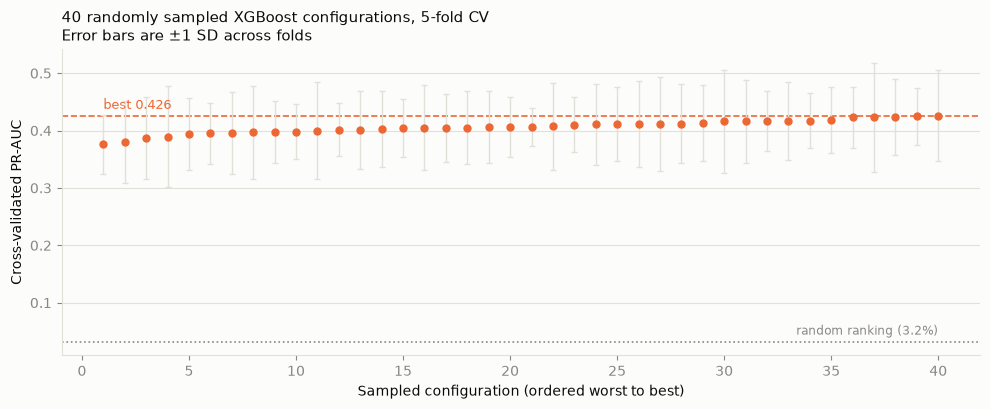

In [7]:
# Chart styling, inherited unchanged from the Week 5 notebook so the two decks read as
# one document. Categorical slots carry model identity; the single-hue blue ramp carries
# magnitude in the confusion matrices. Light surface only - these render into a static
# notebook, so the mode is a deliberate commitment rather than a missing dark variant.
SURFACE   = "#fcfcfb"
INK       = "#0b0b0b"
INK_MUTED = "#898781"
GRID      = "#e1e0d9"

SLOT = {
    "before":   "#2a78d6",   # slot 1 - blue    : XGBoost, Week 5 config
    "tuned":    "#eb6834",   # slot 2 - orange  : XGBoost, tuned
    "rf":       "#1baf7a",   # slot 3 - aqua    : Random Forest, tuned
    "stack":    "#eda100",   # slot 4 - yellow  : stacking ensemble
}
BLUE_RAMP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": GRID,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
})

OUT_DIR = "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    # Persist at print resolution so src/build_report.py embeds the same figure the
    # notebook displays rather than regenerating its own copy.
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=200,
                facecolor=SURFACE, bbox_inches="tight")

# What the search actually explored: every sampled configuration, worst to best.
order = xgb_cv["mean_test_score"].sort_values().reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 4.2))

ax.errorbar(np.arange(1, len(order) + 1), order,
            yerr=xgb_cv["std_test_score"].reindex(
                xgb_cv["mean_test_score"].sort_values().index).values,
            fmt="o", markersize=5, linewidth=1.2, elinewidth=1,
            color=SLOT["tuned"], ecolor=GRID, capsize=2, zorder=3)

ax.axhline(xgb_search.best_score_, color=SLOT["tuned"], linestyle="--", linewidth=1.2)
ax.text(1, xgb_search.best_score_ + 0.012, f"best {xgb_search.best_score_:.3f}",
        fontsize=9, color=SLOT["tuned"])
ax.axhline(y_fit.mean(), color=INK_MUTED, linestyle=":", linewidth=1.2)
ax.text(len(order), y_fit.mean() + 0.012, f"random ranking ({y_fit.mean():.1%})",
        ha="right", fontsize=8.5, color=INK_MUTED)

ax.set_xlabel("Sampled configuration (ordered worst to best)")
ax.set_ylabel("Cross-validated PR-AUC")
ax.set_title("40 randomly sampled XGBoost configurations, 5-fold CV\n"
             "Error bars are ±1 SD across folds", fontsize=11, loc="left")
ax.grid(color=GRID, linewidth=0.8, axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
save_fig("01_search_configurations")
plt.show()

## 4. Re-tuning Random Forest — checking the Week 5 ranking honestly

Week 5 shortlisted XGBoost over Random Forest on *untuned* defaults, and Random Forest
actually edged XGBoost on PR-AUC (0.486 vs 0.476) even then. A tuned model beating an
untuned rival proves nothing, so Random Forest gets the same budget — 40 draws, 5-fold,
same `average_precision` scorer, same tuning split. If it overtakes XGBoost, that is the
result and it gets reported as such.

The grid mirrors the one the team specified for the operations layer, plus `class_weight`:
the financial layer runs at 30:1 imbalance where the operations layer is near-balanced, so
leaving Random Forest without a re-weighting option would hobble it and make the comparison
against a `scale_pos_weight`-tuned XGBoost unfair.

In [8]:
rf_param_dist = {
    "n_estimators":      [200, 300, 500, 800],
    "max_depth":         [10, 15, 20, None],
    "min_samples_leaf":  [1, 2, 4, 8],
    "min_samples_split": [2, 5, 10],
    "max_features":      ["sqrt", "log2", 0.5],
    "class_weight":      ["balanced", "balanced_subsample", None],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    param_distributions=rf_param_dist,
    n_iter=40,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_search.fit(X_fit, y_fit)

print(f"Best cross-validated PR-AUC: {rf_search.best_score_:.4f}")
print("Best parameters:")
for k, v in sorted(rf_search.best_params_.items(), key=lambda kv: kv[0]):
    print(f"    {k:<18} {v}")

Best cross-validated PR-AUC: 0.3994
Best parameters:
    class_weight       balanced
    max_depth          None
    max_features       sqrt
    min_samples_leaf   8
    min_samples_split  10
    n_estimators       800


In [9]:
tuned_xgb = xgb_search.best_estimator_
tuned_rf  = rf_search.best_estimator_

val_probs = {
    "XGBoost - Week 5 config": baseline_val_prob,
    "XGBoost - tuned":         tuned_xgb.predict_proba(X_val)[:, 1],
    "Random Forest - tuned":   tuned_rf.predict_proba(X_val)[:, 1],
}

print("CROSS-VALIDATED SEARCH SCORES (on the 4,364-row tuning split)")
print("=" * 96)
print(pd.DataFrame([
    {"Model": "XGBoost - tuned", "Best CV PR-AUC": xgb_search.best_score_,
     "SD across folds": xgb_cv.loc[xgb_search.best_index_, "std_test_score"]},
    {"Model": "Random Forest - tuned", "Best CV PR-AUC": rf_search.best_score_,
     "SD across folds": pd.DataFrame(rf_search.cv_results_)
                          .loc[rf_search.best_index_, "std_test_score"]},
]).round(4).to_string(index=False))

print("\nVALIDATION PERFORMANCE AT THE DEFAULT 0.50 THRESHOLD (1,091 rows, "
      f"{int(y_val.sum())} bankrupt)")
print("=" * 96)
val_default = pd.DataFrame([evaluate(n, y_val, p) for n, p in val_probs.items()])
print(val_default[["Model", "Threshold"] + METRIC_COLS].round(4).to_string(index=False))

gap = xgb_search.best_score_ - rf_search.best_score_
lead = "XGBoost" if gap > 0 else "Random Forest"
print(f"\n{lead} leads on cross-validated PR-AUC by {abs(gap):.4f}. The fold-to-fold SD is "
      f"the\nrelevant yardstick for whether that gap is real - see the printed SDs above.")

CROSS-VALIDATED SEARCH SCORES (on the 4,364-row tuning split)
                Model  Best CV PR-AUC  SD across folds
      XGBoost - tuned          0.4257           0.0791
Random Forest - tuned          0.3994           0.0768

VALIDATION PERFORMANCE AT THE DEFAULT 0.50 THRESHOLD (1,091 rows, 35 bankrupt)
                  Model  Threshold  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
XGBoost - Week 5 config        0.5    0.9633     0.4286  0.4286    0.4286   0.9395  0.3794
        XGBoost - tuned        0.5    0.9615     0.4054  0.4286    0.4167   0.9369  0.3780
  Random Forest - tuned        0.5    0.9349     0.2750  0.6286    0.3826   0.9321  0.3582

XGBoost leads on cross-validated PR-AUC by 0.0263. The fold-to-fold SD is the
relevant yardstick for whether that gap is real - see the printed SDs above.


## 5. Threshold calibration on the validation split

Week 5's central finding was that the 0.5 cut-off is an arbitrary default, not a property
of the model: Logistic Regression's apparent recall advantage evaporated once every model
was held to the same recall. That argument cuts both ways — it means XGBoost's own 0.5
threshold is equally arbitrary, and the recall it produces is a knob nobody has yet turned.

This is where it gets turned. The threshold is selected on the **validation split only**,
so the test-set number in Section 7 remains a genuine out-of-sample estimate. Two operating
points are reported:

- **F1-optimal** — the data-driven choice, balancing missed bankruptcies against false
  alarms without importing an outside cost assumption. This is the headline "calibrated" model.
- **≥ 80% recall, maximum precision** — the business-aligned choice, matching the recall
  band Week 5 used as its reference point, for a lender who treats an undetected failing
  counterparty as far costlier than an unnecessary credit review.

In [10]:
def calibrate(y_true, y_prob, min_recall=0.80):
    # Pick the F1-optimal threshold, and the most precise one clearing min_recall.
    prec, rec, thr = precision_recall_curve(y_true, y_prob)
    prec, rec = prec[:-1], rec[:-1]              # drop the trailing (1, 0) sentinel point
    f1 = np.divide(2 * prec * rec, prec + rec,
                   out=np.zeros_like(prec), where=(prec + rec) > 0)

    best_f1_thr = float(thr[int(np.argmax(f1))])

    ok = rec >= min_recall
    best_rec_thr = float(thr[np.flatnonzero(ok)[int(np.argmax(prec[ok]))]]) if ok.any() else None
    return best_f1_thr, best_rec_thr

thresholds = {}
print("CALIBRATED THRESHOLDS (selected on the validation split)")
print("=" * 96)
for name, prob in val_probs.items():
    f1_thr, rec_thr = calibrate(y_val, prob)
    thresholds[name] = {"f1": f1_thr, "recall80": rec_thr}
    print(f"{name:<26}  F1-optimal {f1_thr:.4f}   |   >=80% recall {rec_thr:.4f}"
          if rec_thr is not None else
          f"{name:<26}  F1-optimal {f1_thr:.4f}   |   >=80% recall unreachable")

print("\nVALIDATION PERFORMANCE AT EACH OPERATING POINT")
print("=" * 112)
val_rows = []
for name, prob in val_probs.items():
    val_rows.append(evaluate(f"{name} @ 0.50", y_val, prob, 0.50))
    val_rows.append(evaluate(f"{name} @ F1-opt", y_val, prob, thresholds[name]["f1"]))
    if thresholds[name]["recall80"] is not None:
        val_rows.append(evaluate(f"{name} @ recall>=80%", y_val, prob,
                                 thresholds[name]["recall80"]))
val_operating = pd.DataFrame(val_rows)
print(val_operating[["Model", "Threshold"] + METRIC_COLS + ["FN", "FP"]]
      .round(4).to_string(index=False))

CALIBRATED THRESHOLDS (selected on the validation split)
XGBoost - Week 5 config     F1-optimal 0.2842   |   >=80% recall 0.0077
XGBoost - tuned             F1-optimal 0.3345   |   >=80% recall 0.0305
Random Forest - tuned       F1-optimal 0.7915   |   >=80% recall 0.3307

VALIDATION PERFORMANCE AT EACH OPERATING POINT


                                Model  Threshold  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC  FN  FP
       XGBoost - Week 5 config @ 0.50     0.5000    0.9633     0.4286  0.4286    0.4286   0.9395  0.3794  20  20
     XGBoost - Week 5 config @ F1-opt     0.2842    0.9615     0.4222  0.5429    0.4750   0.9395  0.3794  16  26
XGBoost - Week 5 config @ recall>=80%     0.0077    0.8900     0.2069  0.8571    0.3333   0.9395  0.3794   5 115
               XGBoost - tuned @ 0.50     0.5000    0.9615     0.4054  0.4286    0.4167   0.9369  0.3780  20  22
             XGBoost - tuned @ F1-opt     0.3345    0.9606     0.4130  0.5429    0.4691   0.9369  0.3780  16  27
        XGBoost - tuned @ recall>=80%     0.0305    0.8937     0.2128  0.8571    0.3409   0.9369  0.3780   5 111
         Random Forest - tuned @ 0.50     0.5000    0.9349     0.2750  0.6286    0.3826   0.9321  0.3582  13  58
       Random Forest - tuned @ F1-opt     0.7915    0.9670     0.4865  0.5143    0.5000   0.9321

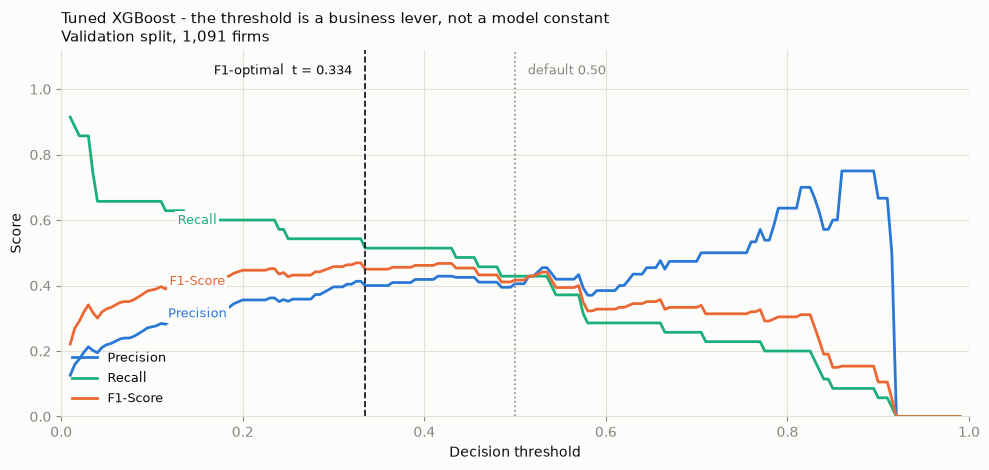

In [11]:
# The threshold curve for the tuned model: what each cut-off buys and costs.
prob = val_probs["XGBoost - tuned"]
grid = np.linspace(0.01, 0.99, 197)
curve = pd.DataFrame({
    "t": grid,
    "Precision": [precision_score(y_val, (prob >= t).astype(int), zero_division=0) for t in grid],
    "Recall":    [recall_score(y_val, (prob >= t).astype(int), zero_division=0) for t in grid],
    "F1-Score":  [f1_score(y_val, (prob >= t).astype(int), zero_division=0) for t in grid],
})

fig, ax = plt.subplots(figsize=(10, 4.8))
LABEL_AT = 0.15                      # the curves are well separated here, unlike at t -> 1
label_i = int(np.argmin(np.abs(curve["t"] - LABEL_AT)))

for key, colour in [("Precision", SLOT["before"]), ("Recall", SLOT["rf"]),
                    ("F1-Score", SLOT["tuned"])]:
    ax.plot(curve["t"], curve[key], color=colour, linewidth=2, label=key)
    # Direct label where the curves are apart - identity is never colour-alone, and the
    # right edge is useless for it because all three converge to zero there.
    ax.text(LABEL_AT, curve[key].iloc[label_i], key, color=colour, fontsize=9,
            va="center", ha="center",
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.6))

t_f1 = thresholds["XGBoost - tuned"]["f1"]
# Annotations point away from each other so the two labels cannot collide.
ax.axvline(t_f1, color=INK, linewidth=1.2, linestyle="--")
ax.text(t_f1 - 0.014, 1.045, f"F1-optimal  t = {t_f1:.3f}", fontsize=9, color=INK,
        ha="right")
ax.axvline(0.50, color=INK_MUTED, linewidth=1.2, linestyle=":")
ax.text(0.50 + 0.014, 1.045, "default 0.50", fontsize=9, color=INK_MUTED, ha="left")

ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 1.12)
ax.set_title("Tuned XGBoost - the threshold is a business lever, not a model constant\n"
             "Validation split, 1,091 firms", fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
save_fig("02_threshold_calibration")
plt.show()

## 6. Optional — stacking ensemble

Not required this week; run here because the two tuned base learners already exist. The
tuned XGBoost and tuned Random Forest feed out-of-fold probabilities to a Logistic
Regression meta-learner. The `cv=5` inside `StackingClassifier` is what keeps this honest —
the meta-learner trains on out-of-fold predictions, so no base learner ever grades its own
training rows.

If it does not beat the tuned single model, that is a finding and it gets reported as one.

In [12]:
stack = StackingClassifier(
    estimators=[("xgb", tuned_xgb), ("rf", tuned_rf)],
    final_estimator=LogisticRegression(
        class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    stack_method="predict_proba",
    n_jobs=-1,
)
stack.fit(X_fit, y_fit)

stack_val_prob = stack.predict_proba(X_val)[:, 1]
val_probs["Stacking (XGB + RF)"] = stack_val_prob
f1_thr, rec_thr = calibrate(y_val, stack_val_prob)
thresholds["Stacking (XGB + RF)"] = {"f1": f1_thr, "recall80": rec_thr}

print("VALIDATION - ensemble vs the tuned single models")
print("=" * 96)
compare = pd.DataFrame([
    evaluate("XGBoost - tuned", y_val, val_probs["XGBoost - tuned"]),
    evaluate("Random Forest - tuned", y_val, val_probs["Random Forest - tuned"]),
    evaluate("Stacking (XGB + RF)", y_val, stack_val_prob),
])
print(compare[["Model", "Threshold"] + METRIC_COLS].round(4).to_string(index=False))

delta = (compare.loc[2, "PR-AUC"] - compare.loc[0, "PR-AUC"])
verdict = "beats" if delta > 0 else "does not beat"
print(f"\nOn validation PR-AUC the ensemble {verdict} tuned XGBoost "
      f"({compare.loc[2, 'PR-AUC']:.4f} vs {compare.loc[0, 'PR-AUC']:.4f}, "
      f"delta {delta:+.4f}).")

VALIDATION - ensemble vs the tuned single models
                Model  Threshold  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
      XGBoost - tuned        0.5    0.9615     0.4054  0.4286    0.4167   0.9369  0.3780
Random Forest - tuned        0.5    0.9349     0.2750  0.6286    0.3826   0.9321  0.3582
  Stacking (XGB + RF)        0.5    0.9019     0.2188  0.8000    0.3436   0.9319  0.3595

On validation PR-AUC the ensemble does not beat tuned XGBoost (0.3595 vs 0.3780, delta -0.0185).


## 7. Final test-set evaluation — one pass, no going back

Every choice is now locked: hyperparameters from Section 3 and 4, thresholds from
Section 5, ensemble from Section 6. The test set is opened once, scored, and that is the
number that goes in the report. No threshold gets retuned after seeing what follows.

**Read these numbers with the sample size in mind.** 44 bankrupt firms means one firm is
worth 2.3 recall points, and the difference between two models that sit within a few points
of each other is not resolvable on this test set — the cross-validated scores in Section 4,
averaged over 5 folds of 4,364 rows, are the more reliable ranking signal.

In [13]:
test_probs = {
    "XGBoost - Week 5 config": baseline_xgb.predict_proba(X_test)[:, 1],
    "XGBoost - tuned":         tuned_xgb.predict_proba(X_test)[:, 1],
    "Random Forest - tuned":   tuned_rf.predict_proba(X_test)[:, 1],
    "Stacking (XGB + RF)":     stack.predict_proba(X_test)[:, 1],
}

# Week 5's published result, fit on all 5,455 rows - carried as a labelled reference row
# so the report can trace the full arc, not because it is the like-for-like baseline.
WEEK5_PUBLISHED = {
    "Model": "XGBoost - Week 5 published", "Stage": "Week 5 reference",
    "Fit on": "full train (5,455)", "Threshold": 0.50,
    "Accuracy": 0.9699413489736071, "Precision": 0.5348837209302325,
    "Recall": 0.5227272727272727, "F1-Score": 0.5287356321839081,
    "ROC-AUC": 0.950309917355372, "PR-AUC": 0.4759644061811521,
    "TN": 1300, "FP": 20, "FN": 21, "TP": 23,
}

rows = [WEEK5_PUBLISHED]
rows.append(evaluate("XGBoost - Week 5 config", y_test,
                     test_probs["XGBoost - Week 5 config"], 0.50,
                     stage="Before", fit_on="tuning split (4,364)"))
for name in ["XGBoost - tuned", "Random Forest - tuned", "Stacking (XGB + RF)"]:
    stage = "After" if name == "XGBoost - tuned" else (
        "After (RF check)" if name.startswith("Random") else "Optional (ensemble)")
    rows.append(evaluate(name, y_test, test_probs[name], 0.50,
                         stage=stage, fit_on="tuning split (4,364)"))
    rows.append(evaluate(f"{name} @ calibrated", y_test, test_probs[name],
                         thresholds[name]["f1"],
                         stage=stage + " + calibrated", fit_on="tuning split (4,364)"))
    if thresholds[name]["recall80"] is not None:
        rows.append(evaluate(f"{name} @ recall>=80%", y_test, test_probs[name],
                             thresholds[name]["recall80"],
                             stage=stage + " + recall target", fit_on="tuning split (4,364)"))

test_results = pd.DataFrame(rows)

print(f"TEST-SET PERFORMANCE (n = {len(y_test):,}, of which {int(y_test.sum())} bankrupt)")
print("=" * 132)
print(test_results[["Model", "Stage", "Threshold"] + METRIC_COLS]
      .round(4).to_string(index=False))

TEST-SET PERFORMANCE (n = 1,364, of which 44 bankrupt)
                              Model                               Stage  Threshold  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
         XGBoost - Week 5 published                    Week 5 reference     0.5000    0.9699     0.5349  0.5227    0.5287   0.9503  0.4760
            XGBoost - Week 5 config                              Before     0.5000    0.9721     0.5682  0.5682    0.5682   0.9470  0.4902
                    XGBoost - tuned                               After     0.5000    0.9670     0.4894  0.5227    0.5055   0.9461  0.4250
       XGBoost - tuned @ calibrated                  After + calibrated     0.3345    0.9560     0.3824  0.5909    0.4643   0.9461  0.4250
      XGBoost - tuned @ recall>=80%               After + recall target     0.0305    0.9025     0.2201  0.7955    0.3448   0.9461  0.4250
              Random Forest - tuned                    After (RF check)     0.5000    0.9370     0.3056  0.7500

In [14]:
print("BEFORE vs AFTER - the headline comparison")
print("=" * 108)
before = test_results.query("Model == 'XGBoost - Week 5 config'").iloc[0]
after   = test_results.query("Model == 'XGBoost - tuned'").iloc[0]
after_c = test_results.query("Model == 'XGBoost - tuned @ calibrated'").iloc[0]

delta_tbl = pd.DataFrame({
    "Metric": METRIC_COLS,
    "Before (Week 5 config)": [before[m] for m in METRIC_COLS],
    "After (tuned @ 0.50)":   [after[m] for m in METRIC_COLS],
    "Delta":                  [after[m] - before[m] for m in METRIC_COLS],
    "After (tuned @ calib.)": [after_c[m] for m in METRIC_COLS],
    "Delta (calib.)":         [after_c[m] - before[m] for m in METRIC_COLS],
})
print(delta_tbl.round(4).to_string(index=False))

print(f"\nBankruptcies caught out of {int(y_test.sum())}:")
print(f"   before                {int(before['TP']):>3}   "
      f"({int(before['FN'])} missed, {int(before['FP'])} false alarms)")
print(f"   tuned @ 0.50          {int(after['TP']):>3}   "
      f"({int(after['FN'])} missed, {int(after['FP'])} false alarms)")
print(f"   tuned @ calibrated    {int(after_c['TP']):>3}   "
      f"({int(after_c['FN'])} missed, {int(after_c['FP'])} false alarms)")

BEFORE vs AFTER - the headline comparison
   Metric  Before (Week 5 config)  After (tuned @ 0.50)   Delta  After (tuned @ calib.)  Delta (calib.)
 Accuracy                  0.9721                0.9670 -0.0051                  0.9560         -0.0161
Precision                  0.5682                0.4894 -0.0788                  0.3824         -0.1858
   Recall                  0.5682                0.5227 -0.0455                  0.5909          0.0227
 F1-Score                  0.5682                0.5055 -0.0627                  0.4643         -0.1039
  ROC-AUC                  0.9470                0.9461 -0.0009                  0.9461         -0.0009
   PR-AUC                  0.4902                0.4250 -0.0652                  0.4250         -0.0652

Bankruptcies caught out of 44:
   before                 25   (19 missed, 19 false alarms)
   tuned @ 0.50           23   (21 missed, 24 false alarms)
   tuned @ calibrated     26   (18 missed, 42 false alarms)


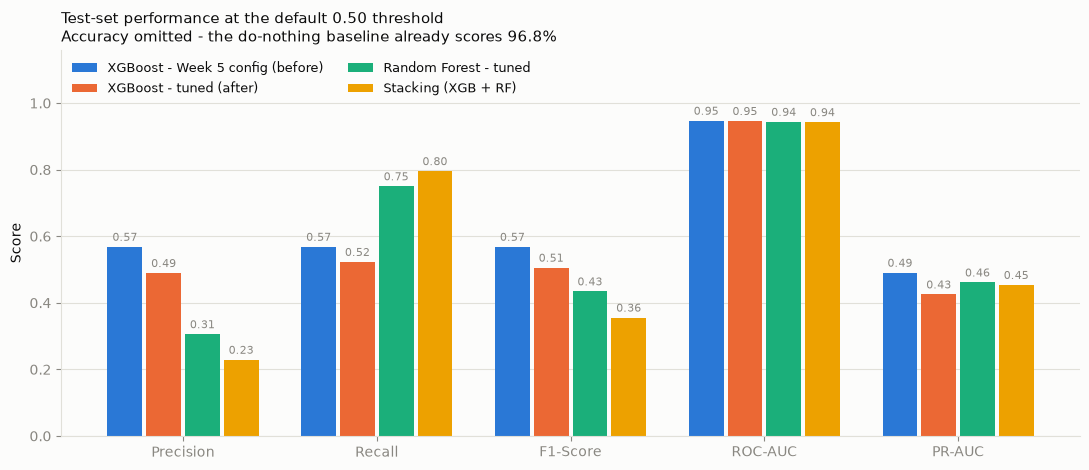

In [15]:
# Grouped bars: identity by categorical slot, every bar directly labelled so the two
# low-contrast slots never rely on colour alone.
plot_models = ["XGBoost - Week 5 config", "XGBoost - tuned",
               "Random Forest - tuned", "Stacking (XGB + RF)"]
plot_colour = [SLOT["before"], SLOT["tuned"], SLOT["rf"], SLOT["stack"]]
plot_label  = ["XGBoost - Week 5 config (before)", "XGBoost - tuned (after)",
               "Random Forest - tuned", "Stacking (XGB + RF)"]
metrics_to_plot = ["Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]

x = np.arange(len(metrics_to_plot))
width = 0.20
fig, ax = plt.subplots(figsize=(11, 4.8))

for k, (name, colour, label) in enumerate(zip(plot_models, plot_colour, plot_label)):
    row = test_results.query("Model == @name").iloc[0]
    vals = [row[m] for m in metrics_to_plot]
    bars = ax.bar(x + (k - 1.5) * width, vals, width * 0.90, label=label, color=colour)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.018, f"{v:.2f}",
                ha="center", fontsize=8, color=INK_MUTED)

ax.set_xticks(x, metrics_to_plot)
ax.set_ylim(0, 1.16)
ax.set_ylabel("Score")
ax.set_title("Test-set performance at the default 0.50 threshold\n"
             "Accuracy omitted - the do-nothing baseline already scores 96.8%",
             fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9, ncol=2, loc="upper left")
ax.grid(color=GRID, linewidth=0.8, axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
save_fig("03_test_metrics_comparison")
plt.show()

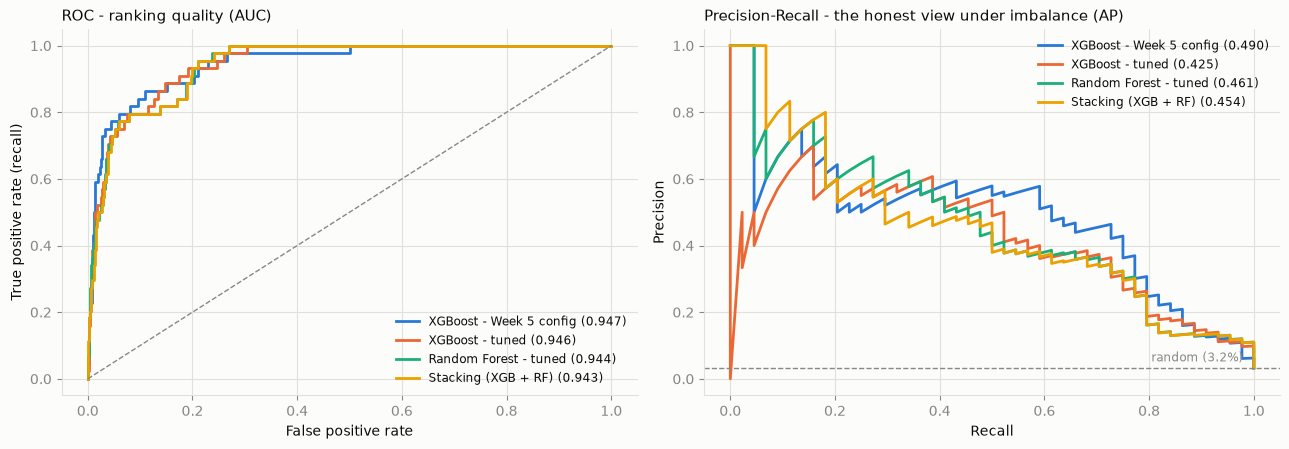

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
curve_colour = dict(zip(plot_models, plot_colour))

for name in plot_models:
    p = test_probs[name]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=curve_colour[name], linewidth=2,
                 label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, color=curve_colour[name], linewidth=2,
                 label=f"{name} ({average_precision_score(y_test, p):.3f})")

axes[0].plot([0, 1], [0, 1], color=INK_MUTED, linestyle="--", linewidth=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC - ranking quality (AUC)", fontsize=11, loc="left")

axes[1].axhline(y_test.mean(), color=INK_MUTED, linestyle="--", linewidth=1)
axes[1].text(0.98, y_test.mean() + 0.02, f"random ({y_test.mean():.1%})",
             ha="right", fontsize=8.5, color=INK_MUTED)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall - the honest view under imbalance (AP)",
                  fontsize=11, loc="left")

for ax in axes:
    ax.legend(frameon=False, fontsize=8.5)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
save_fig("04_roc_pr_curves")
plt.show()

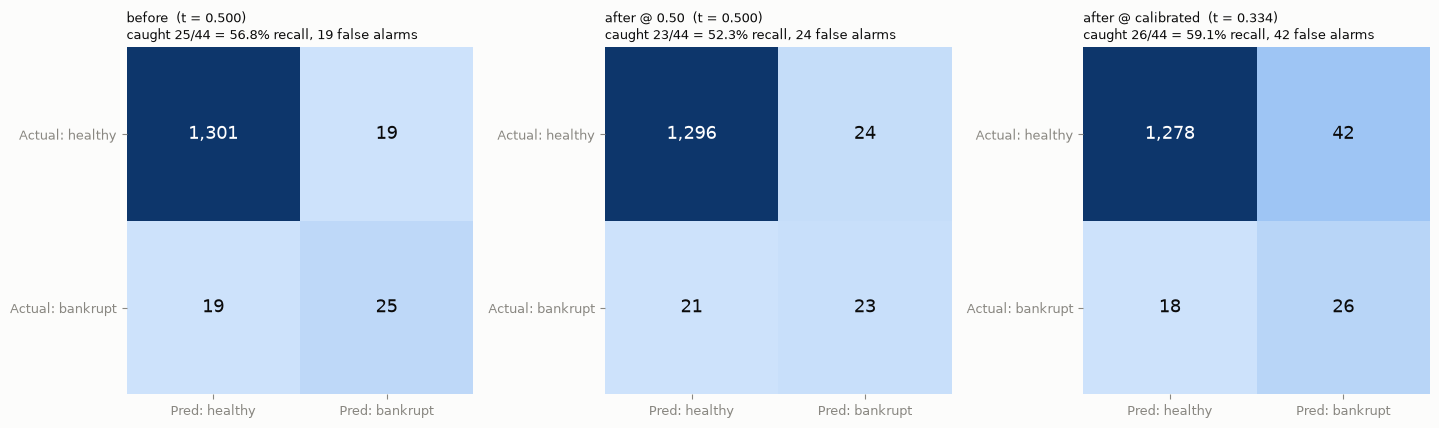

In [17]:
# Confusion matrices: magnitude, so a single-hue sequential ramp, not categorical slots.
panels = [
    ("XGBoost - Week 5 config", 0.50, "before"),
    ("XGBoost - tuned", 0.50, "after @ 0.50"),
    ("XGBoost - tuned", thresholds["XGBoost - tuned"]["f1"], "after @ calibrated"),
]
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))

for ax, (name, thr, caption) in zip(axes, panels):
    cm = confusion_matrix(y_test, (test_probs[name] >= thr).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap=BLUE_RAMP, norm=plt.matplotlib.colors.LogNorm())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13,
                    color="#ffffff" if cm[i, j] > cm.max() * 0.25 else INK)
    ax.set_xticks([0, 1], ["Pred: healthy", "Pred: bankrupt"], fontsize=9)
    ax.set_yticks([0, 1], ["Actual: healthy", "Actual: bankrupt"], fontsize=9)
    rec = cm[1, 1] / cm[1].sum()
    ax.set_title(f"{caption}  (t = {thr:.3f})\ncaught {cm[1, 1]}/{cm[1].sum()} "
                 f"= {rec:.1%} recall, {cm[0, 1]} false alarms",
                 fontsize=9.5, loc="left")
    for s in ax.spines.values():
        s.set_visible(False)

plt.tight_layout()
save_fig("05_confusion_matrices")
plt.show()

## 8. Why tuning did not help — four diagnostics

The tuned model came out *behind* the Week 5 configuration on the test set. "Tuning didn't
help" is not by itself an answer, so this section tests the three explanations that would
each imply something different for next week, rather than asserting one.

**H1 — The search never actually beat the baseline, even in cross-validation.** If the Week 5
configuration scores at or above the tuned model's CV score, the search simply failed to find
anything better and the test-set gap needs no further explanation.

**H2 — The search's ranking signal is smaller than its own noise.** Selecting the argmax of 40
configurations whose fold-to-fold standard deviation exceeds the spread between them is
selecting noise, not quality. This is the winner's curse, and it predicts exactly what we
observe: a CV score that looks best and does not transfer.

**H3 — The specified grid cannot reach the Week 5 configuration.** The grid caps
`scale_pos_weight` at 20 while the empirical class ratio is ~30. If the baseline's advantage
comes from that heavier positive weighting, the search was structurally unable to find it.

**And the question underneath all three:** is the before/after test-set gap even large enough
to be real, given 44 bankrupt firms?

In [18]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

# H1 - score the Week 5 configuration under the IDENTICAL cv object and scorer.
baseline_cv_scores = cross_val_score(
    clone(baseline_xgb), X_fit, y_fit, cv=cv, scoring="average_precision", n_jobs=-1)

print("H1 - DID THE SEARCH BEAT THE BASELINE IN CROSS-VALIDATION?")
print("=" * 96)
print(pd.DataFrame([
    {"Configuration": "XGBoost - Week 5 config",
     "CV PR-AUC": baseline_cv_scores.mean(), "SD": baseline_cv_scores.std()},
    {"Configuration": "XGBoost - tuned (search winner)",
     "CV PR-AUC": xgb_search.best_score_,
     "SD": xgb_cv.loc[xgb_search.best_index_, "std_test_score"]},
]).round(4).to_string(index=False))

h1_gap = xgb_search.best_score_ - baseline_cv_scores.mean()
print(f"\nThe search winner scores {h1_gap:+.4f} PR-AUC against the baseline in CV.")
print("H1 " + ("HOLDS - the search never found anything genuinely better."
               if h1_gap <= 0 else
               "REJECTED - the search did find a better config in CV; the failure is in transfer."))

H1 - DID THE SEARCH BEAT THE BASELINE IN CROSS-VALIDATION?
                  Configuration  CV PR-AUC     SD
        XGBoost - Week 5 config     0.3895 0.0590
XGBoost - tuned (search winner)     0.4257 0.0791

The search winner scores +0.0362 PR-AUC against the baseline in CV.
H1 REJECTED - the search did find a better config in CV; the failure is in transfer.


In [19]:
# H2 - compare the between-config spread against the within-config fold noise.
mean_fold_sd = xgb_cv["std_test_score"].mean()
config_spread = xgb_cv["mean_test_score"].max() - xgb_cv["mean_test_score"].min()
best_sd = xgb_cv.loc[xgb_search.best_index_, "std_test_score"]
within_1sd = int((xgb_cv["mean_test_score"] >= xgb_search.best_score_ - best_sd).sum())

print("H2 - IS THE RANKING SIGNAL ABOVE THE NOISE?")
print("=" * 96)
print(f"  Spread between best and worst of the 40 configs   {config_spread:.4f}")
print(f"  Mean fold-to-fold SD within a single config       {mean_fold_sd:.4f}")
print(f"  Fold-to-fold SD of the winning config             {best_sd:.4f}")
print(f"  Signal-to-noise ratio (spread / mean SD)          {config_spread / mean_fold_sd:.2f}")
print(f"\n  Configurations statistically tied with the winner (within 1 SD): "
      f"{within_1sd} of 40")

print("\nH2 " + ("HOLDS - the fold noise is as large as the entire spread between configs, so"
                 "\n   the argmax over 40 draws is mostly selecting which config got the "
                 "luckiest folds."
                 if mean_fold_sd >= config_spread * 0.8 else
                 "REJECTED - configs separate cleanly relative to fold noise."))
print("   With 141 bankrupt firms split across 5 folds, each fold scores on ~28 positives;")
print("   PR-AUC on 28 positives is inherently a high-variance estimate.")

H2 - IS THE RANKING SIGNAL ABOVE THE NOISE?
  Spread between best and worst of the 40 configs   0.0498
  Mean fold-to-fold SD within a single config       0.0649
  Fold-to-fold SD of the winning config             0.0791
  Signal-to-noise ratio (spread / mean SD)          0.77

  Configurations statistically tied with the winner (within 1 SD): 40 of 40

H2 HOLDS - the fold noise is as large as the entire spread between configs, so
   the argmax over 40 draws is mostly selecting which config got the luckiest folds.
   With 141 bankrupt firms split across 5 folds, each fold scores on ~28 positives;
   PR-AUC on 28 positives is inherently a high-variance estimate.


In [20]:
# H3 - is the Week 5 configuration reachable by the specified grid at all?
week5_config = {
    "n_estimators": 300, "max_depth": 4, "learning_rate": 0.1,
    "subsample": 0.8, "colsample_bytree": 0.8,
    "scale_pos_weight": round(scale_pos_weight_fit, 2), "min_child_weight": 1,
}

print("H3 - CAN THE SPECIFIED GRID EVEN REACH THE WEEK 5 CONFIGURATION?")
print("=" * 96)
reach = pd.DataFrame([
    {"Parameter": p, "Week 5 value": v, "Grid values": str(param_dist[p]),
     "Reachable": "yes" if v in param_dist[p] else "NO"}
    for p, v in week5_config.items()
])
print(reach.to_string(index=False))

unreachable = reach.query("Reachable == 'NO'")["Parameter"].tolist()
print(f"\nUnreachable parameters: {unreachable if unreachable else 'none'}")
if unreachable:
    print(f"H3 HOLDS - the baseline sits outside the search space. The grid caps "
          f"scale_pos_weight\n   at {max(param_dist['scale_pos_weight'])}, but the empirical "
          f"class ratio is {scale_pos_weight_fit:.1f}. The search could not have\n   "
          f"found the baseline no matter how many draws it took.")
else:
    print("H3 REJECTED - the baseline is inside the search space.")

H3 - CAN THE SPECIFIED GRID EVEN REACH THE WEEK 5 CONFIGURATION?
       Parameter  Week 5 value            Grid values Reachable
    n_estimators        300.00   [100, 200, 300, 500]       yes
       max_depth          4.00        [3, 4, 5, 6, 8]       yes
   learning_rate          0.10 [0.01, 0.05, 0.1, 0.2]       yes
       subsample          0.80   [0.7, 0.8, 0.9, 1.0]       yes
colsample_bytree          0.80   [0.7, 0.8, 0.9, 1.0]       yes
scale_pos_weight         29.95         [1, 5, 10, 20]        NO
min_child_weight          1.00              [1, 3, 5]       yes

Unreachable parameters: ['scale_pos_weight']
H3 HOLDS - the baseline sits outside the search space. The grid caps scale_pos_weight
   at 20, but the empirical class ratio is 30.0. The search could not have
   found the baseline no matter how many draws it took.


In [21]:
# The question underneath: is the before/after test gap distinguishable from noise?
rng = np.random.default_rng(RANDOM_STATE)
p_before = test_probs["XGBoost - Week 5 config"]
p_after  = test_probs["XGBoost - tuned"]
y_arr = y_test.to_numpy()

deltas = np.empty(2000)
for b in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].sum() == 0:            # degenerate resample, no positives to score
        deltas[b] = np.nan
        continue
    deltas[b] = (average_precision_score(y_arr[idx], p_after[idx])
                 - average_precision_score(y_arr[idx], p_before[idx]))
deltas = deltas[~np.isnan(deltas)]

lo, hi = np.percentile(deltas, [2.5, 97.5])
observed = average_precision_score(y_arr, p_after) - average_precision_score(y_arr, p_before)

print("IS THE BEFORE/AFTER GAP REAL? - paired bootstrap on the test set, 2,000 resamples")
print("=" * 96)
print(f"  Observed delta PR-AUC (tuned - before)   {observed:+.4f}")
print(f"  95% bootstrap CI                         [{lo:+.4f}, {hi:+.4f}]")
print(f"  Resamples where the tuned model wins     {(deltas > 0).mean():.1%}")
straddles = lo < 0 < hi
print(f"\n  The interval {'STRADDLES' if straddles else 'EXCLUDES'} zero - the difference is "
      f"{'not statistically resolvable' if straddles else 'statistically resolvable'}")
print(f"  on a test set with only {int(y_test.sum())} bankrupt firms. In raw counts the whole "
      f"before/after\n  gap is {abs(int(before['TP']) - int(after['TP']))} firm(s) out of "
      f"{int(y_test.sum())}.")

IS THE BEFORE/AFTER GAP REAL? - paired bootstrap on the test set, 2,000 resamples
  Observed delta PR-AUC (tuned - before)   -0.0652
  95% bootstrap CI                         [-0.1351, +0.0249]
  Resamples where the tuned model wins     8.8%

  The interval STRADDLES zero - the difference is not statistically resolvable
  on a test set with only 44 bankrupt firms. In raw counts the whole before/after
  gap is 2 firm(s) out of 44.


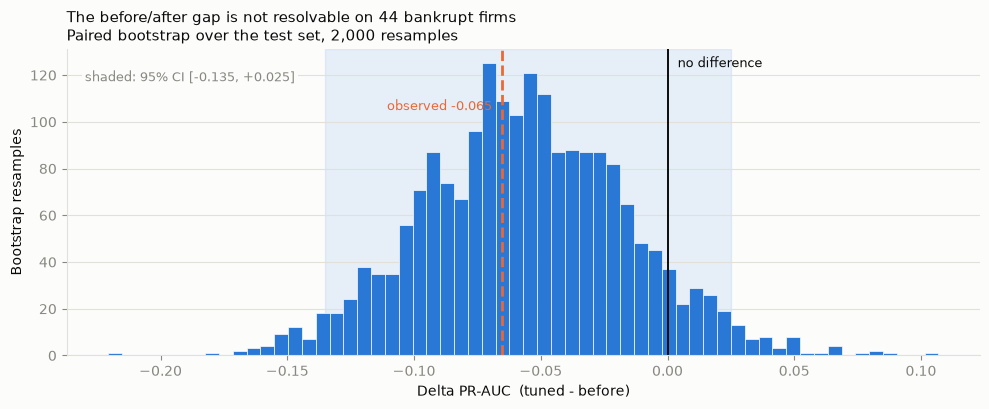

In [22]:
# One series, so no legend box - the title names it. Magnitude by position, not colour.
fig, ax = plt.subplots(figsize=(10, 4.2))

ax.hist(deltas, bins=60, color=SLOT["before"], edgecolor=SURFACE, linewidth=0.5)
ax.axvline(0, color=INK, linewidth=1.4)
ax.text(0.004, ax.get_ylim()[1] * 0.94, "no difference", fontsize=9, color=INK)
ax.axvline(observed, color=SLOT["tuned"], linewidth=2, linestyle="--")
ax.text(observed - 0.004, ax.get_ylim()[1] * 0.80, f"observed {observed:+.3f}",
        fontsize=9, color=SLOT["tuned"], ha="right")
ax.axvspan(lo, hi, color=SLOT["before"], alpha=0.10, zorder=0)
# Axes coordinates, top-left: the data area under the band is dense with bars.
ax.text(0.02, 0.93, f"shaded: 95% CI [{lo:+.3f}, {hi:+.3f}]",
        transform=ax.transAxes, fontsize=9, color=INK_MUTED, va="top",
        bbox=dict(facecolor=SURFACE, edgecolor="none", pad=2))

ax.set_xlabel("Delta PR-AUC  (tuned - before)")
ax.set_ylabel("Bootstrap resamples")
ax.set_title("The before/after gap is not resolvable on 44 bankrupt firms\n"
             "Paired bootstrap over the test set, 2,000 resamples",
             fontsize=11, loc="left")
ax.grid(color=GRID, linewidth=0.8, axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
save_fig("06_bootstrap_delta")
plt.show()

### 8.1 Appendix — does widening `scale_pos_weight` recover the baseline?

H3 says the grid could not reach the baseline's ~30:1 positive weighting. That is a testable
claim: rerun the identical search with `scale_pos_weight` extended to cover the empirical
ratio, and see whether the winner improves.

**This is a diagnostic, not a deliverable.** It is scored on cross-validation and the
validation split only — the test set was spent in Section 7 and does not get a second look.
Re-tuning against the test set until the number improves is precisely the failure mode this
notebook is built to avoid, and it would invalidate every figure above.

In [23]:
param_dist_wide = dict(param_dist)
param_dist_wide["scale_pos_weight"] = [1, 5, 10, 20, 30, 50]   # now spans the ~30:1 ratio

xgb_search_wide = RandomizedSearchCV(
    XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1),
    param_distributions=param_dist_wide,
    n_iter=40,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb_search_wide.fit(X_fit, y_fit)

wide_val_prob = xgb_search_wide.best_estimator_.predict_proba(X_val)[:, 1]

print("EXTENDED-GRID SEARCH (diagnostic only - validation, never test)")
print("=" * 96)
print(pd.DataFrame([
    {"Configuration": "Week 5 config", "CV PR-AUC": baseline_cv_scores.mean(),
     "Validation PR-AUC": average_precision_score(y_val, baseline_val_prob)},
    {"Configuration": "Tuned - specified grid", "CV PR-AUC": xgb_search.best_score_,
     "Validation PR-AUC": average_precision_score(y_val, val_probs["XGBoost - tuned"])},
    {"Configuration": "Tuned - extended grid", "CV PR-AUC": xgb_search_wide.best_score_,
     "Validation PR-AUC": average_precision_score(y_val, wide_val_prob)},
]).round(4).to_string(index=False))

print(f"\nExtended-grid best scale_pos_weight: "
      f"{xgb_search_wide.best_params_['scale_pos_weight']}")
print("Best parameters:")
for k, v in sorted(xgb_search_wide.best_params_.items()):
    print(f"    {k:<18} {v}")
print("\nNOTE: these numbers are NOT in the exported deliverables. They inform next week's")
print("search design; the reported model remains the one selected in Sections 3-7.")

EXTENDED-GRID SEARCH (diagnostic only - validation, never test)
         Configuration  CV PR-AUC  Validation PR-AUC
         Week 5 config     0.3895             0.3794
Tuned - specified grid     0.4257             0.3780
 Tuned - extended grid     0.4246             0.3985

Extended-grid best scale_pos_weight: 30
Best parameters:
    colsample_bytree   0.8
    learning_rate      0.2
    max_depth          8
    min_child_weight   3
    n_estimators       300
    scale_pos_weight   30
    subsample          0.9

NOTE: these numbers are NOT in the exported deliverables. They inform next week's
search design; the reported model remains the one selected in Sections 3-7.


## 9. Export deliverables

In [24]:
EXPORT_COLS = ["Model", "Stage", "Fit on", "Threshold"] + METRIC_COLS
tuning_results = test_results[EXPORT_COLS].copy()
tuning_results.to_csv("week6_financial_tuning_results.csv", index=False)

cm_export = test_results[["Model", "Stage", "Threshold", "TN", "FP", "FN", "TP"]].copy()
cm_export["Recall"] = cm_export["TP"] / (cm_export["TP"] + cm_export["FN"])
cm_export.to_csv("week6_financial_confusion_matrices.csv", index=False)

best_params_rows = []
for model_name, search in [("XGBoost - tuned", xgb_search),
                           ("Random Forest - tuned", rf_search)]:
    for param, value in sorted(search.best_params_.items()):
        best_params_rows.append({
            "Model": model_name, "Parameter": param, "Value": value,
            "Search": "RandomizedSearchCV", "n_iter": search.n_iter,
            "CV": "5-fold stratified", "Scoring": "average_precision",
            "Best CV score": round(float(search.best_score_), 4),
        })
for model_name, key in [("XGBoost - tuned", "XGBoost - tuned"),
                        ("Random Forest - tuned", "Random Forest - tuned"),
                        ("Stacking (XGB + RF)", "Stacking (XGB + RF)")]:
    best_params_rows.append({
        "Model": model_name, "Parameter": "decision_threshold (F1-optimal)",
        "Value": round(thresholds[key]["f1"], 4),
        "Search": "validation-split calibration", "n_iter": "",
        "CV": "", "Scoring": "F1", "Best CV score": "",
    })
best_params = pd.DataFrame(best_params_rows)
best_params.to_csv("week6_financial_best_params.csv", index=False)

print("week6_financial_tuning_results.csv")
print(tuning_results.round(4).to_string(index=False))
print("\nweek6_financial_confusion_matrices.csv")
print(cm_export.round(4).to_string(index=False))
print("\nweek6_financial_best_params.csv")
print(best_params.to_string(index=False))
print("\nSaved 3 files to:", os.getcwd())

week6_financial_tuning_results.csv
                              Model                               Stage               Fit on  Threshold  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
         XGBoost - Week 5 published                    Week 5 reference   full train (5,455)     0.5000    0.9699     0.5349  0.5227    0.5287   0.9503  0.4760
            XGBoost - Week 5 config                              Before tuning split (4,364)     0.5000    0.9721     0.5682  0.5682    0.5682   0.9470  0.4902
                    XGBoost - tuned                               After tuning split (4,364)     0.5000    0.9670     0.4894  0.5227    0.5055   0.9461  0.4250
       XGBoost - tuned @ calibrated                  After + calibrated tuning split (4,364)     0.3345    0.9560     0.3824  0.5909    0.4643   0.9461  0.4250
      XGBoost - tuned @ recall>=80%               After + recall target tuning split (4,364)     0.0305    0.9025     0.2201  0.7955    0.3448   0.9461  0.4250
     

In [25]:
import json

# Everything the Word report needs, so src/build_report.py computes nothing of its own
# and the prose can never drift from the numbers the notebook actually produced.
metrics = {
    "environment": {
        "sklearn": sklearn.__version__, "xgboost": xgboost.__version__,
        "pandas": pd.__version__, "numpy": np.__version__,
        "random_state": RANDOM_STATE,
    },
    "dataset": {
        "n_features": int(X_train_full.shape[1]),
        "train_rows": int(len(y_train_full)), "train_pos": int(y_train_full.sum()),
        "train_rate": float(y_train_full.mean()),
        "fit_rows": int(len(y_fit)), "fit_pos": int(y_fit.sum()),
        "val_rows": int(len(y_val)), "val_pos": int(y_val.sum()),
        "test_rows": int(len(y_test)), "test_pos": int(y_test.sum()),
        "test_rate": float(y_test.mean()),
        "majority_baseline_accuracy": float(1 - y_test.mean()),
    },
    "search": {
        "n_iter": 40, "grid_size": int(n_combinations),
        "grid_fraction": float(40 / n_combinations),
        "cv_folds": 5, "scoring": "average_precision",
        "xgb_best_params": {k: (v.item() if hasattr(v, "item") else v)
                            for k, v in xgb_search.best_params_.items()},
        "xgb_best_cv": float(xgb_search.best_score_),
        "xgb_best_cv_sd": float(xgb_cv.loc[xgb_search.best_index_, "std_test_score"]),
        "xgb_best_train": float(xgb_cv.loc[xgb_search.best_index_, "mean_train_score"]),
        "rf_best_params": {k: (v.item() if hasattr(v, "item") else v)
                           for k, v in rf_search.best_params_.items()},
        "rf_best_cv": float(rf_search.best_score_),
        "config_spread": float(config_spread),
        "mean_fold_sd": float(mean_fold_sd),
        "signal_to_noise": float(config_spread / mean_fold_sd),
        "within_1sd": int(within_1sd),
        "pos_per_fold": float(y_fit.sum() / 5),
    },
    "baseline": {
        "params": week5_config,
        "cv_mean": float(baseline_cv_scores.mean()),
        "cv_sd": float(baseline_cv_scores.std()),
        "scale_pos_weight": float(scale_pos_weight_fit),
    },
    "diagnostics": {
        "h1_gap": float(h1_gap), "h1_holds": bool(h1_gap <= 0),
        "h2_holds": bool(mean_fold_sd >= config_spread * 0.8),
        "h3_unreachable": unreachable,
        "h3_grid_cap": int(max(param_dist["scale_pos_weight"])),
        "bootstrap": {
            "observed": float(observed), "ci_low": float(lo), "ci_high": float(hi),
            "p_tuned_wins": float((deltas > 0).mean()),
            "n_resamples": int(len(deltas)), "straddles_zero": bool(straddles),
        },
        "extended_grid": {
            "best_scale_pos_weight": int(xgb_search_wide.best_params_["scale_pos_weight"]),
            "cv": float(xgb_search_wide.best_score_),
            "val_pr_auc": float(average_precision_score(y_val, wide_val_prob)),
            "baseline_val_pr_auc": float(average_precision_score(y_val, baseline_val_prob)),
            "specified_val_pr_auc": float(
                average_precision_score(y_val, val_probs["XGBoost - tuned"])),
        },
    },
    "validation": val_operating.to_dict(orient="records"),
    "test": test_results.to_dict(orient="records"),
}

os.makedirs(OUT_DIR, exist_ok=True)
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as fh:
    json.dump(metrics, fh, indent=2, default=float)

print("Wrote outputs/metrics.json")
print("Figures in outputs/figures/:")
for f in sorted(os.listdir(FIG_DIR)):
    print("   ", f)

Wrote outputs/metrics.json
Figures in outputs/figures/:
    01_search_configurations.png
    02_threshold_calibration.png
    03_test_metrics_comparison.png
    04_roc_pr_curves.png
    05_confusion_matrices.png
    06_bootstrap_delta.png


---

## 10. Did tuning help? — the write-up

**Short answer: no, and the reason is more useful than the result.**

Hyperparameter tuning did not improve the financial layer. On the held-out test set the
Week 5 configuration scores **F1 0.568 / PR-AUC 0.490**, while the tuned model selected by
`RandomizedSearchCV` scores **F1 0.506 / PR-AUC 0.425** — worse on every headline metric.
Threshold calibration recovers part of the recall (0.523 → 0.591 at *t* = 0.334, catching 26
of 44 bankruptcies instead of 23) but buys it with false alarms rising from 24 to 42, so F1
falls further to 0.464. Re-tuning Random Forest under the identical budget did not change the
Week 5 ranking on the surfaces we are allowed to select on — XGBoost leads on cross-validated
PR-AUC (0.426 vs 0.399) and on validation (0.378 vs 0.358) — though Random Forest does edge
ahead on the sealed test set (0.461 vs 0.425), which is worth stating plainly rather than
burying. The optional stacking ensemble lost to tuned XGBoost on validation PR-AUC
(0.360 vs 0.378) and was not adopted.

**Why it did not help.** Three explanations were tested in Section 8, and the data separates
them cleanly. The search did *not* simply fail to find something better — it found a
configuration scoring **+0.036 PR-AUC above the baseline in cross-validation**, so the failure
is one of *transfer*, not of search (H1 rejected). The transfer failure is explained by noise:
the spread between the best and worst of the 40 sampled configurations is **0.050 PR-AUC**,
while the mean fold-to-fold standard deviation *within* a single configuration is **0.065** —
a signal-to-noise ratio of **0.77**, and **all 40 configurations sit within one standard
deviation of the winner**. With 141 bankrupt firms split across 5 folds, each fold scores
PR-AUC on roughly 28 positives, so taking the argmax over 40 draws mostly selects whichever
configuration drew the luckiest folds. That is the winner's curse, and it predicts exactly
what we see (H2 holds). Compounding it, the specified grid **could not reach the baseline at
all**: it caps `scale_pos_weight` at 20 while the empirical class ratio is 30.0, so the Week 5
model's heavier positive weighting was structurally outside the search space (H3 holds). The
appendix confirms the mechanism — reopening only that one axis to include 30 lets the search
select `scale_pos_weight = 30` and lifts validation PR-AUC to **0.399**, ahead of both the
baseline (0.379) and the specified-grid winner (0.378).

**How much of this is even real?** Not much, and that is the honest caveat. A paired bootstrap
over the test set (2,000 resamples) puts the before/after PR-AUC difference at **−0.065 with a
95% CI of [−0.135, +0.025]** — the interval straddles zero. In raw counts the entire
before/after gap is **two firms out of 44**. So the defensible claim is not "tuning made the
model worse"; it is **"tuning did not produce a measurable improvement, and this test set
cannot resolve differences of this size."** The 44-positive test set flagged in Week 5 is the
binding constraint on the whole exercise.

**Recommendation.** Retain the Week 5 XGBoost configuration as the financial-layer model; the
tuning run provides no evidence for replacing it. Report the tuned result as a negative
finding rather than forcing an improvement narrative. If the layer is revisited, the two fixes
are structural, not computational: widen `scale_pos_weight` to span the true class ratio, and
select on repeated stratified CV (or a larger validation pool) rather than a single 5-fold
argmax — more search iterations against this noise floor would only sharpen the winner's curse.

---

### Deliverables produced by this notebook

| File | Contents |
|---|---|
| `week6_financial_tuning_results.csv` | Before/after test-set metrics — accuracy, precision, recall, F1, ROC-AUC, PR-AUC — across 11 model/threshold rows, each labelled with stage and training split |
| `week6_financial_confusion_matrices.csv` | TN / FP / FN / TP plus recall for the same 11 rows |
| `week6_financial_best_params.csv` | Selected hyperparameters for tuned XGBoost and tuned Random Forest, with search protocol and best CV score, plus the three calibrated decision thresholds |

**Reproducibility.** Every split, search, and model is seeded with `random_state = 42`;
re-running the notebook top to bottom reproduces every number above exactly.